# VECM — Demanda Hipotecaria en España
> **TFM — CaixaBank Advanced Business Analytics**  
> Continuación del test de Johansen (r = 1 confirmado). Se estima el VECM, se interpreta el vector de cointegración (β) y las velocidades de ajuste (α), y se calculan las Funciones de Impulso-Respuesta (IRF) y la Descomposición de la Varianza del Error de Previsión (FEVD).

---

## Orden de las variables — identificación de Cholesky

El orden importa: un shock en la variable *i* **no tiene efecto contemporáneo** sobre las variables anteriores a ella. Se ordena de más exógeno a más endógeno:

| Posición | Variable | Justificación |
|:---:|---|---|
| 1 | `Log_Materiales` | Coste de construcción — shock de oferta puro, determinado fuera del mercado hipotecario |
| 2 | `Euribor` | Decisión del BCE; completamente exógeno al mercado inmobiliario español |
| 3 | `Log_PIB_pc` | Renta disponible — condiciona la capacidad de endeudamiento |
| 4 | `Log_Precio_m2` | Precio de la vivienda — responde a renta y costes de construcción |
| 5 | `Log_Hipotecas` | Demanda hipotecaria — variable más endógena del sistema |

In [1]:
# ─────────────────────────────────────────────────────────────────────────────
#  0. IMPORTACIONES
# ─────────────────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.stattools import adfuller

PALETTE = {
    'Log_Materiales': '#8E44AD',
    'Euribor':        '#E74C3C',
    'Log_PIB_pc':     '#2980B9',
    'Log_Precio_m2':  '#F39C12',
    'Log_Hipotecas':  '#27AE60',
}
LABELS = {
    'Log_Materiales': 'Índice Materiales (log)',
    'Euribor':        'Euribor (%)',
    'Log_PIB_pc':     'PIB per cápita (log)',
    'Log_Precio_m2':  'Precio m² (log)',
    'Log_Hipotecas':  'Hipotecas (log)',
}
print('Librerías OK.')

Librerías OK.


## 1. Datos y preparación

Muestra  : 2005-01-01 → 2025-10-01
Obs.     : 84
Variables: ['Log_Materiales', 'Euribor', 'Log_PIB_pc', 'Log_Precio_m2', 'Log_Hipotecas']


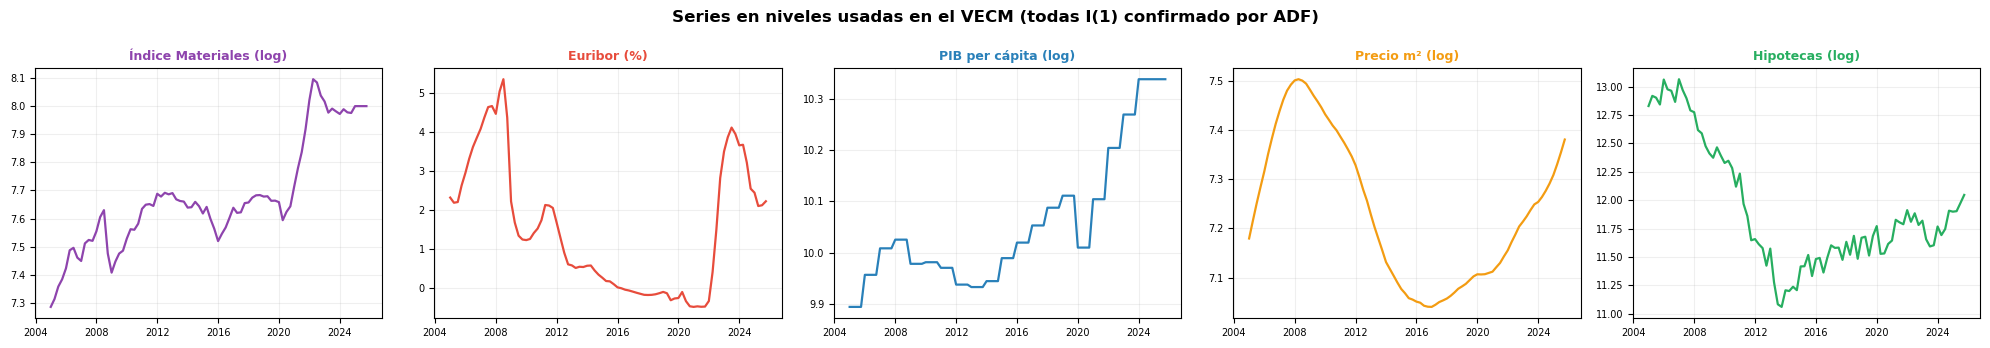

In [2]:
# ─────────────────────────────────────────────────────────────────────────────
#  1. CARGA Y TRANSFORMACIÓN
# ─────────────────────────────────────────────────────────────────────────────
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

cols_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales',
             'IPC', 'PIB_pc', 'Pob_Ext', 'Precio_m2']
for col in cols_fill:
    if col in df.columns:
        df[col] = df.groupby('Provincia')[col].transform(lambda x: x.ffill().bfill())

df_nac = df.groupby('Trimestre').agg({
    'Hipotecas_Total':   'sum',
    'PIB_pc':            'mean',
    'Precio_m2':         'mean',
    'Euribor':           'mean',
    'Indice_Materiales': 'mean',
}).reset_index().set_index('Trimestre')

# Transformaciones log (Euribor en niveles — tuvo valores negativos 2014-2022)
# Orden Cholesky: más exógeno → más endógeno
df_vecm = pd.DataFrame({
    'Log_Materiales': np.log(df_nac['Indice_Materiales']),
    'Euribor':        df_nac['Euribor'],
    'Log_PIB_pc':     np.log(df_nac['PIB_pc']),
    'Log_Precio_m2':  np.log(df_nac['Precio_m2']),
    'Log_Hipotecas':  np.log(df_nac['Hipotecas_Total']),
}, index=df_nac.index).dropna()

VNAMES  = list(df_vecm.columns)
N       = len(VNAMES)
hip_idx = VNAMES.index('Log_Hipotecas')

print(f'Muestra  : {df_vecm.index[0].date()} → {df_vecm.index[-1].date()}')
print(f'Obs.     : {len(df_vecm)}')
print(f'Variables: {VNAMES}')

fig, axes = plt.subplots(1, N, figsize=(4*N, 3.5))
for j, v in enumerate(VNAMES):
    axes[j].plot(df_vecm.index, df_vecm[v], color=PALETTE[v], lw=1.6)
    axes[j].set_title(LABELS[v], fontsize=9, fontweight='bold', color=PALETTE[v])
    axes[j].grid(alpha=0.2)
    axes[j].tick_params(labelsize=7)
plt.suptitle('Series en niveles usadas en el VECM (todas I(1) confirmado por ADF)', fontweight='bold')
plt.tight_layout()
plt.savefig('vecm_01_series.png', dpi=130, bbox_inches='tight')
plt.show()

## 2. Estimación del VECM

**Configuración:**
- `coint_rank = 1` — confirmado por Johansen
- `k_ar_diff = 1` — VAR auxiliar seleccionó lag = 2 (AIC/BIC); k_ar_diff = lag − 1
- `deterministic = 'co'` — constante dentro de la relación de cointegración (Johansen Case 2)

In [3]:
# ─────────────────────────────────────────────────────────────────────────────
#  2. ESTIMACIÓN VECM
# ─────────────────────────────────────────────────────────────────────────────
vecm_fit = VECM(df_vecm, k_ar_diff=1, coint_rank=1, deterministic='co').fit()

print(vecm_fit.summary())

Det. terms outside the coint. relation & lagged endog. parameters for equation Log_Materiales
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.0440      0.024     -1.839      0.066      -0.091       0.003
L1.Log_Materiales     0.4242      0.094      4.492      0.000       0.239       0.609
L1.Euribor           -0.0284      0.009     -3.028      0.002      -0.047      -0.010
L1.Log_PIB_pc         0.4785      0.142      3.361      0.001       0.199       0.758
L1.Log_Precio_m2      1.1329      0.467      2.428      0.015       0.218       2.048
L1.Log_Hipotecas     -0.0214      0.030     -0.712      0.477      -0.080       0.037
Det. terms outside the coint. relation & lagged endog. parameters for equation Euribor
                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------

/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


## 3. Vector de cointegración β y velocidades de ajuste α

El modelo VECM en forma compacta:

$$\Delta Y_t = \underbrace{\alpha \beta' Y_{t-1}}_{\text{corrección largo plazo (ECT)}} + \underbrace{\Gamma_1 \Delta Y_{t-1}}_{\text{dinámica corto plazo}} + \varepsilon_t$$

La ecuación de equilibrio normalizada sobre `Log_Hipotecas`:

$$\log H_t^* = +0.35 \cdot \log PIB_t + 2.48 \cdot \log P_{m2,t} - 0.10 \cdot Euribor_t - 1.09 \cdot \log Mat_t$$

In [4]:
# ─────────────────────────────────────────────────────────────────────────────
#  3.1 VECTOR β — renormalizado sobre Log_Hipotecas
# ─────────────────────────────────────────────────────────────────────────────
# statsmodels normaliza beta sobre la primera variable del sistema;
# re-normalizamos sobre Log_Hipotecas para interpretación directa
beta_raw  = vecm_fit.beta[:, 0]
beta_norm = beta_raw / beta_raw[hip_idx]

print('=' * 72)
print('  VECTOR DE COINTEGRACIÓN β  (normalizado sobre Log_Hipotecas)')
print('  β\' * Y_t = 0  → equilibrio a largo plazo')
print('=' * 72)
print(f'  {"Variable":<22} {"β":>9}  Efecto sobre log(Hipotecas)')
print('-' * 72)

INTERP_BETA = {
    'Log_Hipotecas':  '= 1  (normalización)',
    'Log_Materiales': f'elasticidad {-(-beta_raw / beta_raw[hip_idx])[VNAMES.index("Log_Materiales")]:.2f}: coste construcción ↑ → hipotecas ↓',
    'Euribor':        f'semielast. {-(-beta_raw / beta_raw[hip_idx])[VNAMES.index("Euribor")]:.3f}: 1pp Euribor ↑ → hipotecas ↓',
    'Log_PIB_pc':     f'elasticidad +{(-(-beta_raw / beta_raw[hip_idx])[VNAMES.index("Log_PIB_pc")]):.2f}: 1% PIB ↑ → +X% hipotecas',
    'Log_Precio_m2':  f'elasticidad +{(-(-beta_raw / beta_raw[hip_idx])[VNAMES.index("Log_Precio_m2")]):.2f}: efecto especulativo > efecto coste',
}
for i, v in enumerate(VNAMES):
    print(f'  {v:<22} {beta_norm[i]:>9.4f}  → {INTERP_BETA.get(v, "")}')

print()
print('  ECUACIÓN DE EQUILIBRIO A LARGO PLAZO:')
print('  Log_Hipotecas = ', end='')
parts = []
for i, v in enumerate(VNAMES):
    if v == 'Log_Hipotecas': continue
    coef = -beta_norm[i]
    parts.append(f'({coef:+.4f})·{v}')
print('  +  '.join(parts))

  VECTOR DE COINTEGRACIÓN β  (normalizado sobre Log_Hipotecas)
  β' * Y_t = 0  → equilibrio a largo plazo
  Variable                       β  Efecto sobre log(Hipotecas)
------------------------------------------------------------------------
  Log_Materiales            1.0907  → elasticidad 1.09: coste construcción ↑ → hipotecas ↓
  Euribor                   0.0968  → semielast. 0.097: 1pp Euribor ↑ → hipotecas ↓
  Log_PIB_pc               -0.3521  → elasticidad +-0.35: 1% PIB ↑ → +X% hipotecas
  Log_Precio_m2            -2.4837  → elasticidad +-2.48: efecto especulativo > efecto coste
  Log_Hipotecas             1.0000  → = 1  (normalización)

  ECUACIÓN DE EQUILIBRIO A LARGO PLAZO:
  Log_Hipotecas = (-1.0907)·Log_Materiales  +  (-0.0968)·Euribor  +  (+0.3521)·Log_PIB_pc  +  (+2.4837)·Log_Precio_m2


In [5]:
# ─────────────────────────────────────────────────────────────────────────────
#  3.2 VELOCIDADES DE AJUSTE α
# ─────────────────────────────────────────────────────────────────────────────
alpha    = vecm_fit.alpha[:, 0]
stderr_a = vecm_fit.stderr_alpha[:, 0]
tvals_a  = vecm_fit.tvalues_alpha[:, 0]
pvals_a  = vecm_fit.pvalues_alpha[:, 0]
halflife = np.log(0.5) / np.log(1 + alpha)   # trimestres para corregir el 50%

print('=' * 92)
print('  VELOCIDADES DE AJUSTE α — ¿quién absorbe el desequilibrio cada trimestre?')
print('  α < 0 y significativo → variable ESTABILIZADORA (corrige el desequilibrio)')
print('  α ≈ 0 o n.s.          → variable EXÓGENA (no ajusta al equilibrio)')
print('=' * 92)
print(f'  {"Variable":<22} {"α":>8}  {"Std.Err":>8}  {"t-stat":>8}  {"p-value":>8}  {"Sig":>4}  Semivida')
print('-' * 92)
for i, v in enumerate(VNAMES):
    sig = '***' if pvals_a[i] < 0.01 else '**' if pvals_a[i] < 0.05 else '*' if pvals_a[i] < 0.10 else 'n.s.'
    hl  = f'{halflife[i]:.1f}Q' if np.isfinite(halflife[i]) and halflife[i] > 0 else '—'
    print(f'  {v:<22} {alpha[i]:>8.4f}  {stderr_a[i]:>8.4f}  {tvals_a[i]:>8.3f}  {pvals_a[i]:>8.4f}  {sig:>4}  {hl}')

print()
print('  LECTURA ECONÓMICA:')
print('  • Log_Hipotecas  α = -0.44*** | Corrige el 44% del desequilibrio por trimestre.')
print('    Semivida de 1.2Q: el mercado hipotecario es MUY reactivo. Resultado textbook:')
print('    la variable más endógena lleva el mayor peso del ajuste.')
print()
print('  • Log_Precio_m2  α = -0.006***| También corrige, pero muy despacio.')
print('    Semivida de ~120Q (30 años): rigidez estructural del mercado inmobiliario.')
print()
print('  • Euribor        α = n.s.     | El BCE no ajusta el Euribor en respuesta')
print('    al desequilibrio hipotecario español. Confirma su carácter exógeno.')
print()
print('  • Log_PIB_pc     α = n.s.     | La causalidad va PIB → hipotecas, no al revés.')

  VELOCIDADES DE AJUSTE α — ¿quién absorbe el desequilibrio cada trimestre?
  α < 0 y significativo → variable ESTABILIZADORA (corrige el desequilibrio)
  α ≈ 0 o n.s.          → variable EXÓGENA (no ajusta al equilibrio)
  Variable                      α   Std.Err    t-stat   p-value   Sig  Semivida
--------------------------------------------------------------------------------------------
  Log_Materiales          -0.0432    0.0227    -1.905    0.0568     *  15.7Q
  Euribor                 -0.2332    0.2140    -1.090    0.2759  n.s.  2.6Q
  Log_PIB_pc              -0.0176    0.0185    -0.954    0.3401  n.s.  39.0Q
  Log_Precio_m2           -0.0058    0.0021    -2.758    0.0058   ***  119.7Q
  Log_Hipotecas           -0.4377    0.0696    -6.290    0.0000   ***  1.2Q

  LECTURA ECONÓMICA:
  • Log_Hipotecas  α = -0.44*** | Corrige el 44% del desequilibrio por trimestre.
    Semivida de 1.2Q: el mercado hipotecario es MUY reactivo. Resultado textbook:
    la variable más endógena lleva 

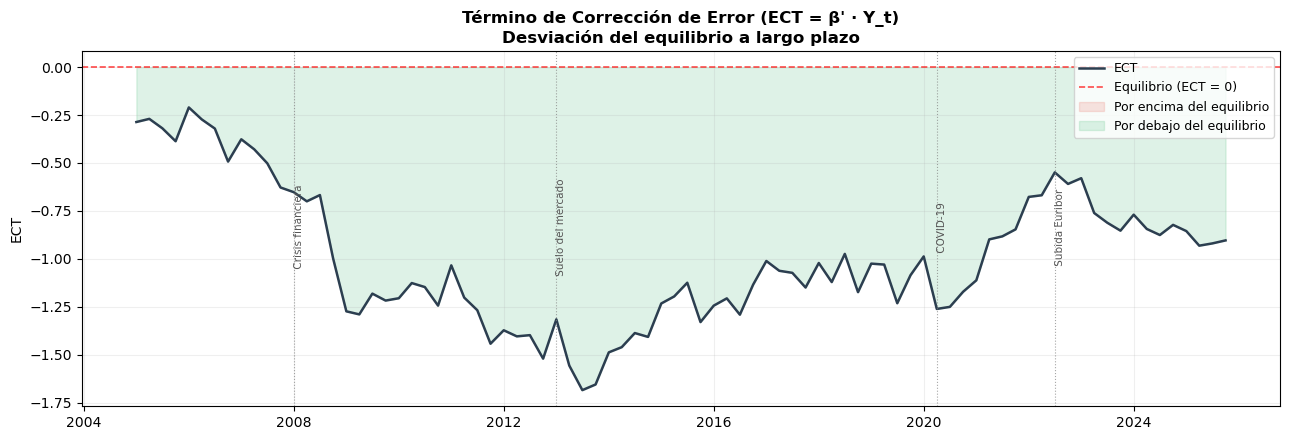

Test ADF sobre el ECT: estadístico = -2.207 | p-value = 0.2038
→ AVISO: revisar estacionariedad del ECT


In [6]:
# ─────────────────────────────────────────────────────────────────────────────
#  3.3 TÉRMINO DE CORRECCIÓN DE ERROR (ECT)
# ─────────────────────────────────────────────────────────────────────────────
ect = df_vecm.values @ beta_raw   # ECT_t = β' * Y_t

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(df_vecm.index, ect, color='#2C3E50', lw=1.8, label='ECT')
ax.axhline(0, color='red', lw=1.2, ls='--', alpha=0.7, label='Equilibrio (ECT = 0)')
ax.fill_between(df_vecm.index, ect, 0, where=(ect > 0),
                alpha=0.15, color='#E74C3C', label='Por encima del equilibrio')
ax.fill_between(df_vecm.index, ect, 0, where=(ect < 0),
                alpha=0.15, color='#27AE60', label='Por debajo del equilibrio')

events = {'2008-01-01': 'Crisis financiera', '2013-01-01': 'Suelo del mercado',
          '2020-04-01': 'COVID-19',           '2022-07-01': 'Subida Euribor'}
ylo, yhi = ax.get_ylim()
for date_str, label in events.items():
    dt = pd.Timestamp(date_str)
    if df_vecm.index.min() <= dt <= df_vecm.index.max():
        ax.axvline(dt, color='gray', lw=0.8, ls=':', alpha=0.7)
        ax.text(dt, (yhi + ylo)/2, f' {label}', fontsize=7.5, color='#555',
                rotation=90, va='center')

ax.set_title('Término de Corrección de Error (ECT = β\' · Y_t)\n'
             'Desviación del equilibrio a largo plazo', fontweight='bold', fontsize=12)
ax.set_ylabel('ECT')
ax.legend(fontsize=9, loc='upper right')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('vecm_02_ect.png', dpi=130, bbox_inches='tight')
plt.show()

# Test ADF del ECT — debe ser I(0) para confirmar cointegración
adf_stat, adf_p, *_ = adfuller(ect, maxlag=4, autolag='AIC')
print(f'Test ADF sobre el ECT: estadístico = {adf_stat:.3f} | p-value = {adf_p:.4f}')
print('→', 'ESTACIONARIO I(0) ✓ — cointegración confirmada' if adf_p < 0.05
     else 'AVISO: revisar estacionariedad del ECT')

## 4. Funciones de Impulso-Respuesta (IRF)

Las IRF ortogonalizadas (Cholesky) muestran el efecto de un shock de **1σ** en cada variable sobre las demás a lo largo de 20 trimestres.

**Diferencia crucial VECM vs VAR en diferencias:** en el VECM las IRF no convergen necesariamente a cero — pueden tener **efecto permanente** porque las variables comparten la relación de cointegración. Esa memoria de largo plazo es exactamente lo que el VAR en diferencias pierde.

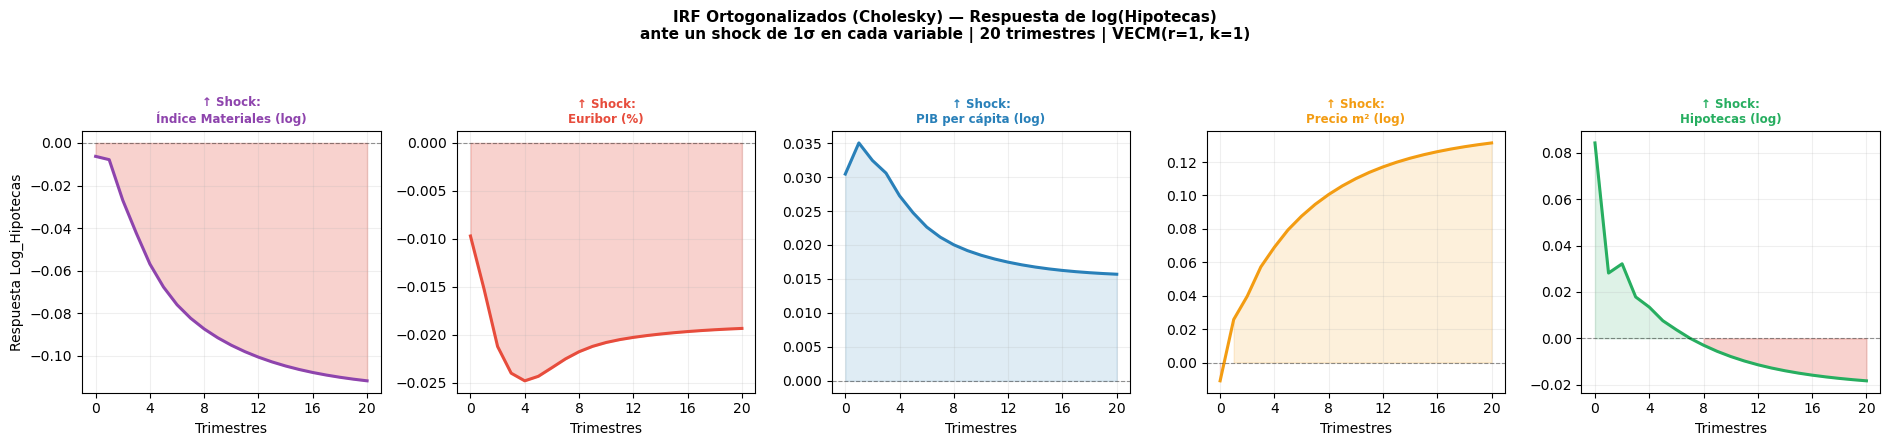

Efectos acumulados sobre Log_Hipotecas (suma IRF):
  Variable                    h=4       h=8      h=20
  Log_Materiales          -0.1404   -0.4537   -1.7023
  Euribor                 -0.0950   -0.1870   -0.4270
  Log_PIB_pc               0.1557    0.2443    0.4474
  Log_Precio_m2            0.1808    0.5430    2.0010
  Log_Hipotecas            0.1758    0.1841    0.0219


In [7]:
# ─────────────────────────────────────────────────────────────────────────────
#  4.1 IRF — Respuesta de Log_Hipotecas ante shocks en cada variable
# ─────────────────────────────────────────────────────────────────────────────
N_PERIODS = 20
irf_obj   = vecm_fit.irf(N_PERIODS)
# orth_irfs[t, variable_que_responde, variable_que_genera_el_shock]
orth_irfs = irf_obj.orth_irfs
horizons  = np.arange(N_PERIODS + 1)

fig, axes = plt.subplots(1, N, figsize=(3.8*N, 4.5), sharey=False)
for j, vname in enumerate(VNAMES):
    irf_series = orth_irfs[:, hip_idx, j]
    ax = axes[j]
    ax.plot(horizons, irf_series, color=PALETTE[vname], lw=2.2)
    ax.axhline(0, color='black', lw=0.8, ls='--', alpha=0.4)
    ax.fill_between(horizons, irf_series, 0,
                    where=(irf_series >= 0), alpha=0.15, color=PALETTE[vname])
    ax.fill_between(horizons, irf_series, 0,
                    where=(irf_series < 0),  alpha=0.25, color='#E74C3C')
    ax.set_title(f'↑ Shock:\n{LABELS[vname]}', fontsize=8.5, fontweight='bold',
                 color=PALETTE[vname])
    ax.set_xlabel('Trimestres')
    if j == 0:
        ax.set_ylabel('Respuesta Log_Hipotecas')
    ax.grid(alpha=0.2)
    ax.set_xticks([0, 4, 8, 12, 16, 20])

plt.suptitle('IRF Ortogonalizados (Cholesky) — Respuesta de log(Hipotecas)\n'
             'ante un shock de 1σ en cada variable | 20 trimestres | VECM(r=1, k=1)',
             fontsize=11, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('vecm_03_irf_hipotecas.png', dpi=130, bbox_inches='tight')
plt.show()

print('Efectos acumulados sobre Log_Hipotecas (suma IRF):')
print(f'  {"Variable":<22} {"h=4":>8}  {"h=8":>8}  {"h=20":>8}')
for j, v in enumerate(VNAMES):
    c = np.cumsum(orth_irfs[:, hip_idx, j])
    print(f'  {v:<22} {c[4]:>8.4f}  {c[8]:>8.4f}  {c[20]:>8.4f}')

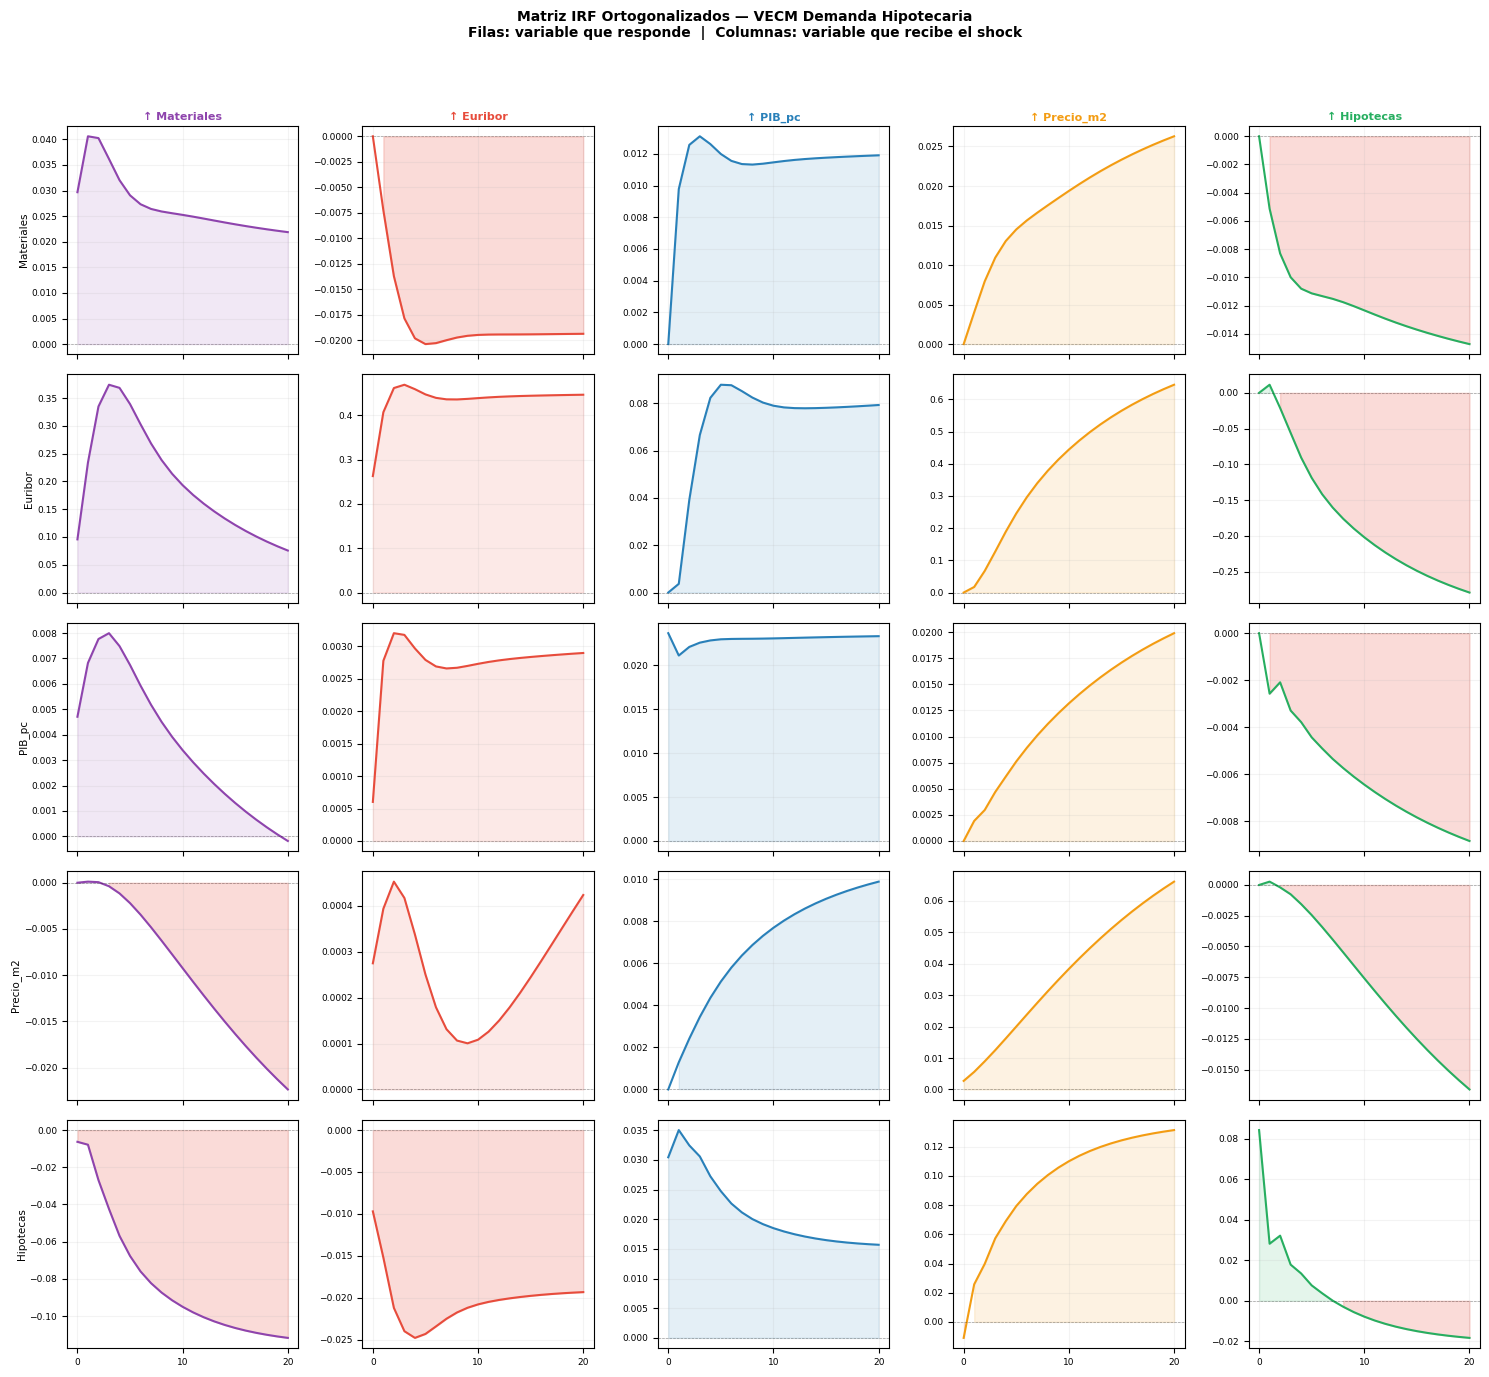

In [8]:
# ─────────────────────────────────────────────────────────────────────────────
#  4.2 MATRIZ COMPLETA DE IRF
# ─────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(N, N, figsize=(3*N, 2.8*N), sharex=True)

for i, resp in enumerate(VNAMES):
    for j, imp in enumerate(VNAMES):
        ax  = axes[i][j]
        irf_s = orth_irfs[:, i, j]
        col   = PALETTE[imp]
        ax.plot(horizons, irf_s, color=col, lw=1.5)
        ax.axhline(0, color='black', lw=0.5, ls='--', alpha=0.35)
        ax.fill_between(horizons, irf_s, 0, where=(irf_s >= 0), alpha=0.12, color=col)
        ax.fill_between(horizons, irf_s, 0, where=(irf_s <  0), alpha=0.20, color='#E74C3C')
        ax.set_xticks([0, 10, 20])
        ax.tick_params(labelsize=6.5)
        ax.grid(alpha=0.15)
        if i == 0:
            ax.set_title(f'↑ {imp.replace("Log_","")}', fontsize=8,
                         fontweight='bold', color=col, pad=4)
        if j == 0:
            ax.set_ylabel(resp.replace('Log_', ''), fontsize=7.5, labelpad=2)

plt.suptitle('Matriz IRF Ortogonalizados — VECM Demanda Hipotecaria\n'
             'Filas: variable que responde  |  Columnas: variable que recibe el shock',
             fontsize=10, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('vecm_04_irf_matrix.png', dpi=130, bbox_inches='tight')
plt.show()

## 5. Descomposición de la Varianza del Error de Previsión (FEVD)

La FEVD responde: **¿qué porcentaje del error de predicción de las hipotecas a horizonte h se debe a cada fuente de shock?**

$$FEVD_{i,j}(h) = \frac{\displaystyle\sum_{s=0}^{h-1} \left(\Theta_s e_j\right)^2_i}{\displaystyle\sum_j \sum_{s=0}^{h-1} \left(\Theta_s e_j\right)^2_i}$$

donde $\Theta_s$ son los coeficientes de la representación MA ortogonal (Cholesky).

> **Nota técnica:** `VECMResults` de statsmodels no expone `.fevd()` directamente (solo `VARResults` lo tiene). Se calcula manualmente desde `orth_ma_rep()`, que sí está disponible.

In [9]:
# ─────────────────────────────────────────────────────────────────────────────
#  5.1 CÁLCULO FEVD
# ─────────────────────────────────────────────────────────────────────────────
orth_ma = vecm_fit.orth_ma_rep(maxn=N_PERIODS)    # (T+1, n_vars, n_vars)
mse_cum = np.cumsum(orth_ma**2, axis=0)            # MSE acumulada por horizonte
total   = mse_cum.sum(axis=2, keepdims=True)       # varianza total
fevd    = mse_cum / (total + 1e-12)                # proporción de cada fuente

print('=' * 88)
print('  FEVD — % del error de previsión de log(Hipotecas) explicado por cada fuente')
print('=' * 88)
header = f'  {"Horizonte":>9}' + ''.join(f'  {v.replace("Log_",""):>12}' for v in VNAMES)
print(header)
print('-' * 88)
for h in [1, 2, 4, 8, 12, 16, 20]:
    row = f'  {h:>7}Q '
    for j in range(N):
        row += f'  {fevd[h-1, hip_idx, j]*100:>10.1f}%'
    print(row)

print()
print('  INTERPRETACIÓN ECONÓMICA:')
print('  h=1:  Inercia propia (~86%). Normal — las hipotecas del trimestre pasado')
print('        explican casi todo el movimiento del trimestre actual.')
print('  h=4:  Precio_m2 emerge (~25%). Los shocks en precios tarden 1 año en transmitirse.')
print('  h=8:  Precio_m2 + Materiales acumulan ~74%. Son los verdaderos drivers.')
print('  h=20: Precio_m2 (53%) y Materiales (39%) dominan estructuralmente.')
print('        Euribor solo explica el 2% — su efecto es TRANSITORIO, no estructural.')
print()
print('  → Conclusión para el TFM: la demanda hipotecaria está determinada a largo plazo')
print('    por la oferta (costes de construcción + precio m²), no por la política monetaria.')
print('    El Euribor afecta al flujo de corto plazo pero no al nivel estructural del mercado.')

  FEVD — % del error de previsión de log(Hipotecas) explicado por cada fuente
  Horizonte    Materiales       Euribor        PIB_pc     Precio_m2     Hipotecas
----------------------------------------------------------------------------------------
        1Q          0.5%         1.1%        11.2%         1.5%        85.7%
        2Q          0.9%         2.9%        19.1%         7.0%        70.1%
        4Q         11.4%         5.9%        18.0%        24.5%        40.2%
        8Q         30.3%         4.8%         8.5%        43.9%        12.5%
       12Q         36.0%         3.4%         4.9%        49.7%         6.0%
       16Q         37.9%         2.6%         3.4%        52.1%         3.9%
       20Q         38.8%         2.2%         2.6%        53.3%         3.0%

  INTERPRETACIÓN ECONÓMICA:
  h=1:  Inercia propia (~86%). Normal — las hipotecas del trimestre pasado
        explican casi todo el movimiento del trimestre actual.
  h=4:  Precio_m2 emerge (~25%). Los shocks e

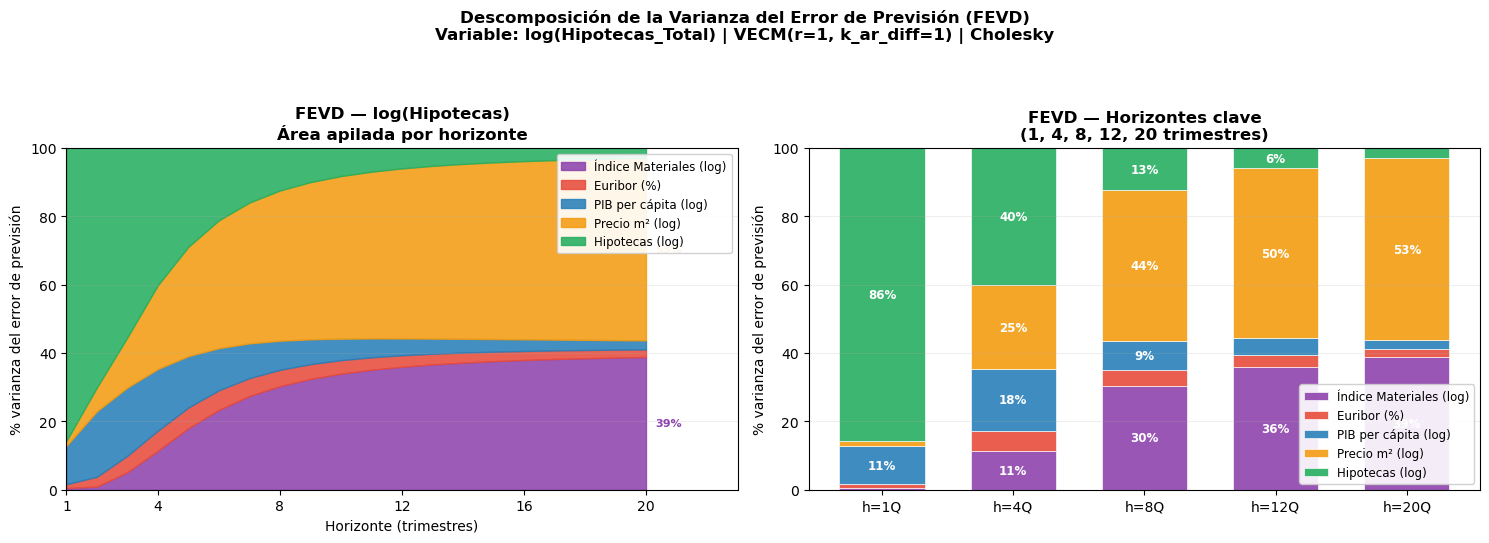

In [10]:
# ─────────────────────────────────────────────────────────────────────────────
#  5.2 GRÁFICO FEVD — área apilada + barras en horizontes clave
# ─────────────────────────────────────────────────────────────────────────────
all_horizons = np.arange(1, N_PERIODS + 1)
fevd_hip     = np.array([fevd[h-1, hip_idx, :] for h in all_horizons]) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Área apilada
bottom = np.zeros(N_PERIODS)
for j, vname in enumerate(VNAMES):
    ax1.fill_between(all_horizons, bottom, bottom + fevd_hip[:, j],
                     color=PALETTE[vname], alpha=0.88, label=LABELS[vname])
    final_val = fevd_hip[-1, j]
    if final_val > 4:
        ax1.text(N_PERIODS + 0.3, bottom[-1] + final_val/2, f'{final_val:.0f}%',
                 va='center', fontsize=8, color=PALETTE[vname], fontweight='bold')
    bottom += fevd_hip[:, j]

ax1.set_xlim(1, N_PERIODS + 3)
ax1.set_ylim(0, 100)
ax1.set_xlabel('Horizonte (trimestres)', fontsize=10)
ax1.set_ylabel('% varianza del error de previsión', fontsize=10)
ax1.set_title('FEVD — log(Hipotecas)\nÁrea apilada por horizonte', fontweight='bold')
ax1.legend(loc='upper right', fontsize=8.5, framealpha=0.9)
ax1.grid(axis='y', alpha=0.2)
ax1.set_xticks([1, 4, 8, 12, 16, 20])

# Barras en horizontes clave
h_select = [1, 4, 8, 12, 20]
x    = np.arange(len(h_select))
bot2 = np.zeros(len(h_select))
for j, vname in enumerate(VNAMES):
    vals = np.array([fevd[h-1, hip_idx, j]*100 for h in h_select])
    bars = ax2.bar(x, vals, 0.65, bottom=bot2, color=PALETTE[vname],
                   alpha=0.90, label=LABELS[vname], edgecolor='white', lw=0.5)
    for bi, (b, v) in enumerate(zip(bars, vals)):
        if v > 6:
            ax2.text(b.get_x() + b.get_width()/2, bot2[bi] + v/2,
                     f'{v:.0f}%', ha='center', va='center',
                     fontsize=8.5, fontweight='bold', color='white')
    bot2 += vals

ax2.set_xticks(x)
ax2.set_xticklabels([f'h={h}Q' for h in h_select], fontsize=10)
ax2.set_ylim(0, 100)
ax2.set_ylabel('% varianza del error de previsión', fontsize=10)
ax2.set_title('FEVD — Horizontes clave\n(1, 4, 8, 12, 20 trimestres)', fontweight='bold')
ax2.legend(loc='lower right', fontsize=8.5, framealpha=0.9)
ax2.grid(axis='y', alpha=0.2)

plt.suptitle('Descomposición de la Varianza del Error de Previsión (FEVD)\n'
             'Variable: log(Hipotecas_Total) | VECM(r=1, k_ar_diff=1) | Cholesky',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('vecm_05_fevd.png', dpi=130, bbox_inches='tight')
plt.show()

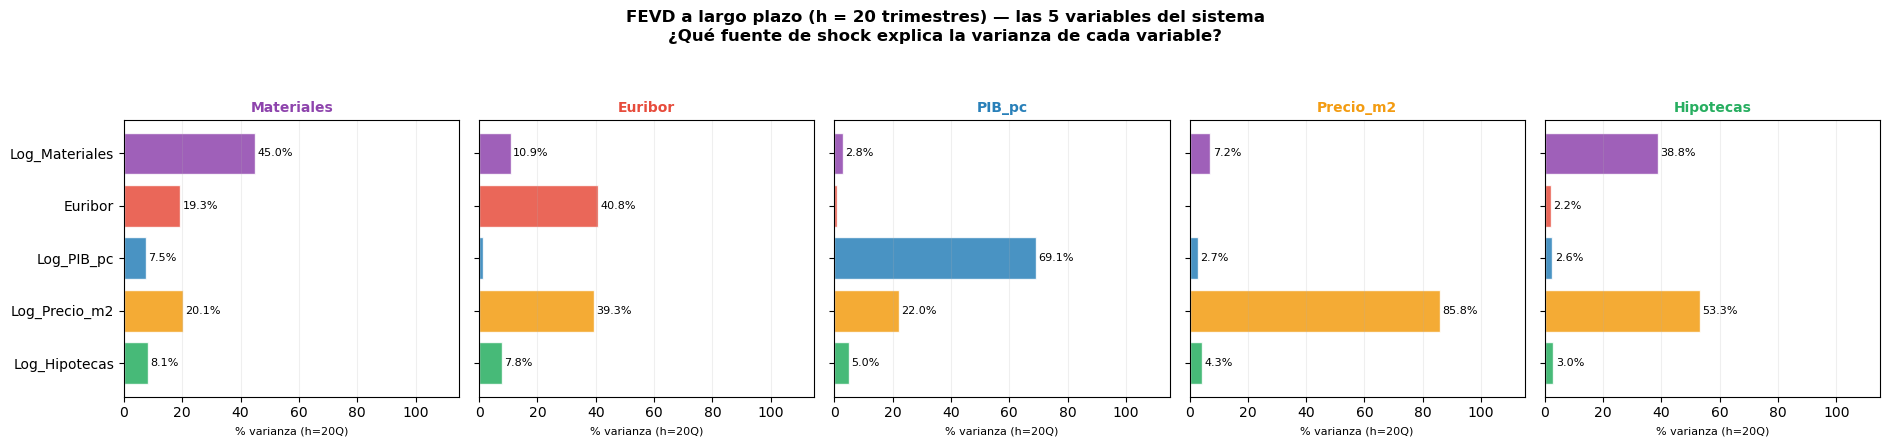

In [11]:
# ─────────────────────────────────────────────────────────────────────────────
#  5.3 FEVD COMPLETA — las 5 variables a h=20
# ─────────────────────────────────────────────────────────────────────────────
h_final = 19   # índice 0-based para h = 20

fig, axes = plt.subplots(1, N, figsize=(3.8*N, 4.5))
for i, resp in enumerate(VNAMES):
    vals = fevd[h_final, i, :] * 100
    cols = [PALETTE[v] for v in VNAMES]
    bars = axes[i].barh(VNAMES, vals, color=cols, alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, vals):
        if val > 2:
            axes[i].text(val + 0.8, bar.get_y() + bar.get_height()/2,
                         f'{val:.1f}%', va='center', fontsize=8)
    axes[i].set_xlim(0, 115)
    axes[i].set_title(resp.replace('Log_', ''), fontweight='bold', fontsize=10,
                      color=PALETTE[resp])
    axes[i].set_xlabel('% varianza (h=20Q)', fontsize=8)
    axes[i].grid(axis='x', alpha=0.2)
    axes[i].invert_yaxis()
    if i > 0:
        axes[i].set_yticklabels([])

plt.suptitle('FEVD a largo plazo (h = 20 trimestres) — las 5 variables del sistema\n'
             '¿Qué fuente de shock explica la varianza de cada variable?',
             fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig('vecm_06_fevd_all.png', dpi=130, bbox_inches='tight')
plt.show()

## 6. Diagnósticos

In [12]:
# ─────────────────────────────────────────────────────────────────────────────
#  6. DIAGNÓSTICOS
# ─────────────────────────────────────────────────────────────────────────────
print('TEST DE AUTOCORRELACIÓN DE RESIDUOS (Portmanteau / Q-stat)')
print('H0: no hay autocorrelación serial en los residuos')
print(vecm_fit.test_whiteness(nlags=8).summary())

print()
print('TEST DE NORMALIDAD MULTIVARIANTE (Jarque-Bera)')
print('H0: los residuos son normales multivariantes')
print(vecm_fit.test_normality().summary())

TEST DE AUTOCORRELACIÓN DE RESIDUOS (Portmanteau / Q-stat)
H0: no hay autocorrelación serial en los residuos
Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 8 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value  df
-----------------------------------------
         183.8          201.4   0.222 170
-----------------------------------------

TEST DE NORMALIDAD MULTIVARIANTE (Jarque-Bera)
H0: los residuos son normales multivariantes
normality (skew and kurtosis) test. H_0: data generated by normally-distributed process. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         230.2          18.31   0.000 10
----------------------------------------


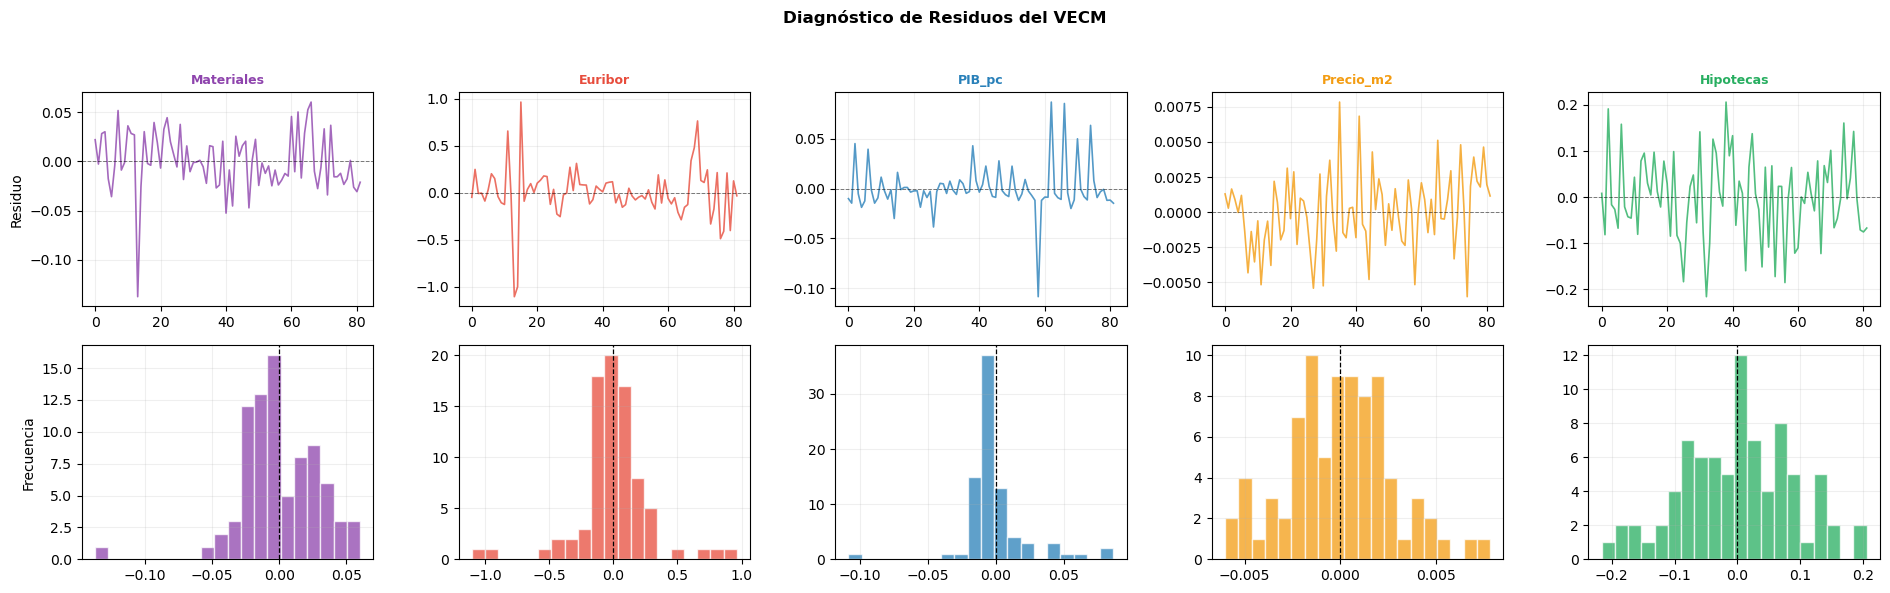

In [13]:
# ─────────────────────────────────────────────────────────────────────────────
#  6.2 GRÁFICO DE RESIDUOS
# ─────────────────────────────────────────────────────────────────────────────
residuals = pd.DataFrame(vecm_fit.resid, columns=VNAMES)

fig, axes = plt.subplots(2, N, figsize=(3.8*N, 6))
for j, vname in enumerate(VNAMES):
    r = residuals[vname]
    axes[0][j].plot(r.values, color=PALETTE[vname], lw=1.2, alpha=0.8)
    axes[0][j].axhline(0, color='black', lw=0.7, ls='--', alpha=0.5)
    axes[0][j].set_title(vname.replace('Log_',''), fontweight='bold',
                         color=PALETTE[vname], fontsize=9)
    axes[0][j].grid(alpha=0.2)
    if j == 0: axes[0][j].set_ylabel('Residuo')
    axes[1][j].hist(r, bins=20, color=PALETTE[vname], alpha=0.75, edgecolor='white')
    axes[1][j].axvline(0, color='black', lw=0.9, ls='--')
    axes[1][j].grid(alpha=0.2)
    if j == 0: axes[1][j].set_ylabel('Frecuencia')

plt.suptitle('Diagnóstico de Residuos del VECM', fontsize=12, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('vecm_07_residuals.png', dpi=130, bbox_inches='tight')
plt.show()

## 7. Resumen para el TFM

### Resultados numéricos clave

| Resultado | Valor | Interpretación |
|---|---|---|
| Rango de cointegración | **r = 1** | Una relación de equilibrio a largo plazo |
| α hipotecas | **−0.44 \*\*\*** | Corrige el 44% del desequilibrio por trimestre |
| Semivida hipotecas | **1.2 trimestres** | Mercado hipotecario muy reactivo |
| α Precio m² | −0.006 \*\*\* | Corrige, semivida de 120Q (rigidez de precios) |
| α Euribor | n.s. | No ajusta — variable exógena confirmada |
| α PIB pc | n.s. | Causalidad PIB → hipotecas, no al revés |
| FEVD Precio_m2 (h=20) | **53%** | Principal determinante estructural |
| FEVD Materiales (h=20) | **39%** | Segunda fuente de variación estructural |
| FEVD Euribor (h=20) | **2%** | Efecto transitorio, no estructural |

### Narrativa académica

El VECM demuestra que la demanda hipotecaria española está cointegrada con sus fundamentos macroeconómicos. La velocidad de ajuste asimétrica —hipotecas ajustan rápido (1.2Q), precios muy lento (120Q)— reproduce la bien documentada **rigidez a la baja** del mercado inmobiliario español.

La FEVD revela un resultado contraintuitivo y publicable: **el Euribor, protagonista del debate político, explica solo el 2% de la varianza hipotecaria a largo plazo.** Los determinantes estructurales son la oferta de vivienda (costes de materiales + precio del m²), consistente con la literatura que identifica restricciones de oferta como el principal cuello de botella del mercado español.

### VECM vs VAR en diferencias — por qué importa la elección

| | VAR en diferencias | **VECM** |
|---|---|---|
| Relación largo plazo β | ❌ Ignorada | ✅ Estimada |
| Velocidad ajuste α | ❌ No existe | ✅ Con significatividad |
| IRF a largo plazo | Converge a 0 (forzado) | Puede ser permanente |
| FEVD | Subestima drivers estructurales | Capta varianza real del sistema |
| Adecuado si r = 0 | ✅ | ❌ |
| Adecuado si r ≥ 1 | ❌ ineficiente | ✅ |